# 10 · Improvement Experiments: What We Tried to Raise Accuracy

Phase 2 did not stop at one LSTM. This notebook collects **every idea we tested** to make the 6-hour forecast more accurate, and shows which ones helped.

All experiments use the **same rolling backtest** (4 folds, Jan 2013 to Dec 2014) and are scored on the **same measured hours**, so the numbers can be compared directly. Nothing here is tuned on the test periods.

| Part | Question |
| --- | --- |
| 1 | Which training choices made the LSTM better? (the improvement journey) |
| 2 | Is another network design better than the LSTM? (GRU, TCN, Bi-LSTM, CNN-LSTM, Attention, Transformer) |
| 3 | Does a classical time-series model (ARIMA) do better? |
| 4 | Can the "change" idea also improve XGBoost and the hybrid? |
| 5 | Should the hybrid learn its weights (stacking)? |
| 6 | What would a weather forecast add? (a what-if upper bound) |
| 7 | Other honest ways to read accuracy: AQI within one category, yes/no health alerts, shorter horizons |

The slow network experiments are trained by `dl_experiments.py` (30 to 60 minutes) and saved in `data/GeneratedOutput/05.DeepLearning/experiments/`. Everything else runs inside this notebook in about a minute.

In [1]:
import os
import sys

# Find the project folder (the one that contains config.py) and work from there
ROOT = os.getcwd()
while not os.path.exists(os.path.join(ROOT, "config.py")):
    ROOT = os.path.dirname(ROOT)
os.chdir(ROOT)
sys.path.append(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config

FIG = "reports/figures"
OUT = "data/GeneratedOutput/05.DeepLearning"
os.makedirs(FIG, exist_ok=True)
os.makedirs(OUT, exist_ok=True)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

In [2]:
from xgboost import XGBRegressor
from scipy.optimize import nnls
from data_loader import load_raw_data, clean_data
from features import build_features, get_feature_columns
from backtest import make_folds, compute_metrics, observed_only
from xgboost_model import train_and_predict_xgboost
from aqi import category_accuracy, within_one_category_accuracy

EXP = f"{OUT}/experiments"
clean = clean_data(load_raw_data(config.RAW_FILE))
df = build_features(clean)

# Final Phase 2 forecasts of every model (saved by notebook 03)
final = pd.read_csv(f"{OUT}/all_model_predictions.csv", index_col="forecast_made_at", parse_dates=["forecast_made_at", "forecast_for"])
scored = observed_only(final)


def average_scores(actual, forecast, folds):
    """MAE, RMSE and R2 in each fold, then the average over the 4 folds."""
    rows = [compute_metrics(actual[folds == f], forecast[folds == f]) for f in sorted(folds.unique())]
    return pd.DataFrame(rows).mean().round(3)


def experiment_scores(name):
    """Scores of one experiment saved by dl_experiments.py."""
    file = f"{EXP}/{name.replace(', ', '_').replace(' ', '_')}.csv"
    preds = observed_only(pd.read_csv(file, index_col=0, parse_dates=True))
    return average_scores(preds["target"], preds["forecast"], preds["fold"])


print("Final models:", [c for c in final.columns if c not in ["forecast_for", "actual", "target_observed", "fold"]])

Final models: ['Persistence', 'Seasonal naive', 'XGBoost', 'LSTM', 'TCN', 'Hybrid']


## 1. The improvement journey: how the LSTM got better step by step

In [3]:
journey = pd.DataFrame({
    "1. LSTM predicts the PM2.5 level (MSE loss)": experiment_scores("LSTM, level target, MSE loss"),
    "2. Predict the 6-hour CHANGE instead": experiment_scores("LSTM, change target, MSE loss"),
    "3. L1 loss (the metric we report)": experiment_scores("LSTM"),
    "4. Average of 3 training runs (seeds)": average_scores(scored["actual"], scored["LSTM"], scored["fold"]),
    "5. Hybrid: XGBoost + LSTM + TCN": average_scores(scored["actual"], scored["Hybrid"], scored["fold"]),
}).T
journey["MAE gain vs step 1"] = (1 - journey["MAE"] / journey["MAE"].iloc[0]).map("{:.1%}".format)
journey.to_csv(f"{OUT}/improvement_journey.csv")
journey

,MAE,RMSE,R2,MAE gain vs step 1
1. LSTM predicts the PM2.5 level (MSE loss),36.743,56.190,0.645,0.0%
2. Predict the 6-hour CHANGE instead,36.108,55.620,0.652,1.7%
3. L1 loss (the metric we report),34.995,55.915,0.648,4.8%
4. Average of 3 training runs (seeds),34.278,54.375,0.667,6.7%
5. Hybrid: XGBoost + LSTM + TCN,33.760,53.410,0.680,8.1%


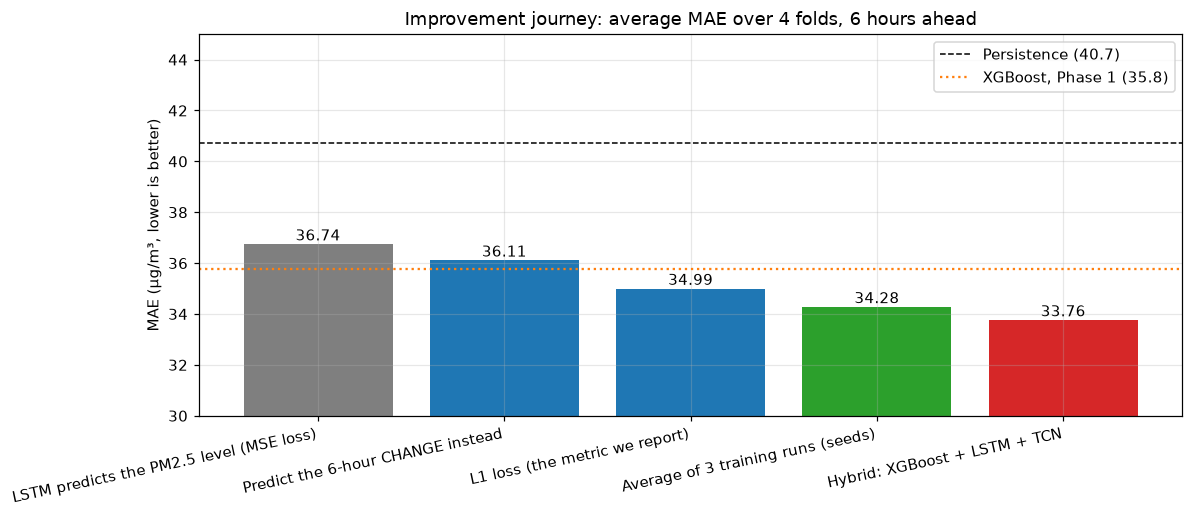

In [4]:
persistence_mae = average_scores(scored["actual"], scored["Persistence"], scored["fold"])["MAE"]
xgb_mae = average_scores(scored["actual"], scored["XGBoost"], scored["fold"])["MAE"]

fig, ax = plt.subplots(figsize=(11, 4.8))
labels = [name.split(". ", 1)[1] for name in journey.index]
bars = ax.bar(range(len(journey)), journey["MAE"], color=["tab:gray", "tab:blue", "tab:blue", "tab:green", "tab:red"])
ax.axhline(persistence_mae, color="black", linestyle="--", linewidth=1, label=f"Persistence ({persistence_mae:.1f})")
ax.axhline(xgb_mae, color="tab:orange", linestyle=":", linewidth=1.5, label=f"XGBoost, Phase 1 ({xgb_mae:.1f})")
for bar, value in zip(bars, journey["MAE"]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.15, f"{value:.2f}", ha="center")
ax.set_xticks(range(len(journey)), labels, rotation=12, ha="right")
ax.set_ylim(30, 45)
ax.set_ylabel("MAE (µg/m³, lower is better)")
ax.set_title("Improvement journey: average MAE over 4 folds, 6 hours ahead")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(f"{FIG}/20_improvement_journey.png")
plt.show()

- **Predicting the change** helps first: persistence means "change = 0", so the network starts from a strong baseline and only learns the correction.
- **L1 loss** gave the biggest single gain: it trains on the same error we report (MAE) and is less pulled around by rare extreme spikes than MSE.
- **Averaging 3 training runs** removes part of the randomness of one run.
- The **hybrid** adds XGBoost, whose errors differ from the networks' errors, and is the best model.

## 2. Is another network design better than the LSTM?

In [5]:
designs = ["LSTM", "GRU", "TCN", "Bi-LSTM", "CNN-LSTM", "Attention LSTM", "Transformer"]
networks = pd.DataFrame({name: experiment_scores(name) for name in designs}).T.sort_values("MAE")
networks.index.name = "network (one training run each)"
networks.to_csv(f"{OUT}/network_designs.csv")
networks

,MAE,RMSE,R2
network (one training run each),,,
TCN,34.470,54.988,0.660
GRU,34.552,54.823,0.661
Attention LSTM,34.592,54.848,0.663
LSTM,34.995,55.915,0.648
Bi-LSTM,35.078,55.838,0.649
CNN-LSTM,35.160,55.777,0.651
Transformer,35.450,55.805,0.649


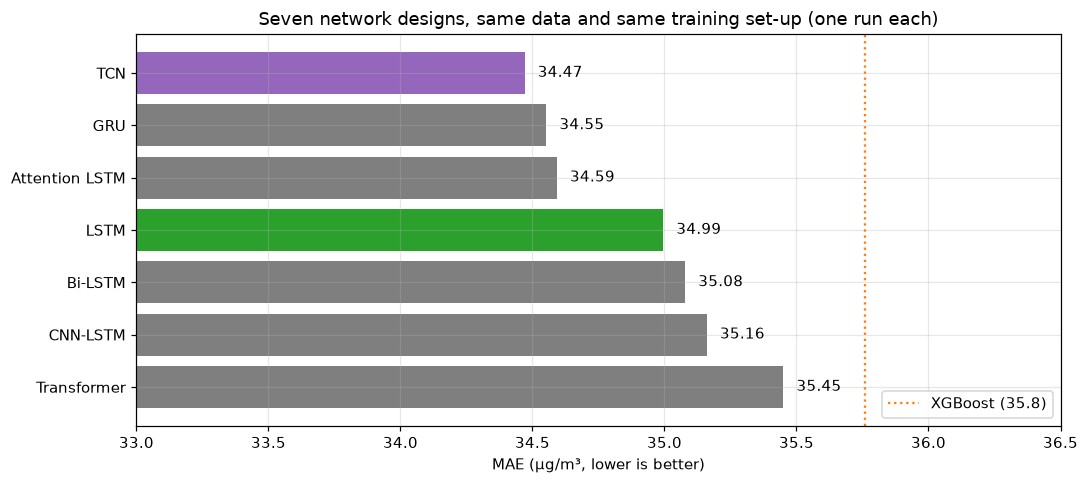

Spread between best and worst design: 0.98 µg/m³


In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ["tab:green" if n == "LSTM" else "tab:purple" if n == "TCN" else "tab:gray" for n in networks.index]
bars = ax.barh(networks.index[::-1], networks["MAE"][::-1], color=colors[::-1])
for bar, value in zip(bars, networks["MAE"][::-1]):
    ax.text(value + 0.05, bar.get_y() + bar.get_height() / 2, f"{value:.2f}", va="center")
ax.axvline(xgb_mae, color="tab:orange", linestyle=":", linewidth=1.5, label=f"XGBoost ({xgb_mae:.1f})")
ax.set_xlim(33, 36.5)
ax.set_xlabel("MAE (µg/m³, lower is better)")
ax.set_title("Seven network designs, same data and same training set-up (one run each)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{FIG}/21_network_designs.png")
plt.show()
print(f"Spread between best and worst design: {networks['MAE'].max() - networks['MAE'].min():.2f} µg/m³")

All seven designs land within about one µg/m³ of each other, which is about as much as one design changes between two training runs. More complex networks (attention, Transformer) do **not** help here. We kept the **LSTM** and the **TCN** because they are simple, well understood, and represent the two main families (recurrent and convolutional) that the project brief asks for.

## 3. A classical time-series model: ARIMA

ARIMA(p, 1, 0) models the hourly change of PM2.5 as a linear combination of the last *p* changes. We fit it on the training rows of each fold with least squares and forecast 6 steps ahead, one hour at a time.

In [7]:
def arima_forecast(train, test, p):
    """ARIMA(p,1,0): fit on the training rows, forecast every test hour 6 hours ahead."""
    pm25 = df["pm25"].values
    change = np.diff(pm25, prepend=np.nan)          # change[t] = pm25[t] - pm25[t-1]
    n_train = len(train)                            # training rows come first in df

    # Least squares: next change = c + sum of phi_k * (change k hours ago)
    rows = np.arange(p + 1, n_train - 1)
    X = np.column_stack([change[rows - k] for k in range(p)] + [np.ones(len(rows))])
    y = change[rows + 1]
    coef = np.linalg.lstsq(X, y, rcond=None)[0]
    phi, c = coef[:p], coef[p]

    # Forecast 6 steps ahead for every test hour
    t = np.arange(n_train, n_train + len(test))
    recent = np.column_stack([change[t - k] for k in range(p)])   # newest change first
    level = pm25[t].astype(float)
    for step in range(config.HORIZON):
        next_change = recent @ phi + c
        level = level + next_change
        recent = np.column_stack([next_change, recent[:, :-1]])
    return np.clip(level, 0, None)


arima_rows = {}
for p in [3, 12, 24]:
    preds = []
    for fold, train, test in make_folds(df):
        preds.append(pd.DataFrame({"forecast": arima_forecast(train, test, p), "fold": fold,
                                   "target": test["target"], "target_observed": test["target_observed"]}, index=test.index))
    preds = observed_only(pd.concat(preds))
    arima_rows[f"ARIMA({p},1,0)"] = average_scores(preds["target"], preds["forecast"], preds["fold"])
arima = pd.DataFrame(arima_rows).T
arima.loc["Persistence"] = average_scores(scored["actual"], scored["Persistence"], scored["fold"])
arima.loc["Hybrid"] = average_scores(scored["actual"], scored["Hybrid"], scored["fold"])
arima

,MAE,RMSE,R2
"ARIMA(3,1,0)",40.652,65.155,0.520
"ARIMA(12,1,0)",40.888,63.957,0.538
"ARIMA(24,1,0)",41.202,63.322,0.548
Persistence,40.732,65.312,0.518
Hybrid,33.760,53.410,0.680


ARIMA is about as good as persistence. It only sees past PM2.5 and only learns **linear** patterns, while PM2.5 jumps when the wind changes. Our networks and XGBoost also use weather and learn non-linear effects.

## 4. The "change" idea for XGBoost

Predicting the 6-hour change with an L1 loss was the biggest gain for the LSTM. Does the same trick help XGBoost, and through it the hybrid?

In [8]:
def xgboost_change_forecast(train, test):
    """XGBoost that predicts the 6-hour CHANGE with an absolute-error (L1) loss."""
    columns = get_feature_columns(train)
    train = observed_only(train)
    model = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8,
                         colsample_bytree=0.8, objective="reg:absoluteerror", random_state=config.RANDOM_SEED)
    model.fit(train[columns], train["target"] - train["pm25"])
    return np.clip(test["pm25"].values + model.predict(test[columns]), 0, None)


xgb_change = pd.concat([pd.Series(xgboost_change_forecast(train, test), index=test.index) for _, train, test in make_folds(df)])
scored = scored.assign(**{"XGBoost (change, L1)": xgb_change.loc[scored.index]})
scored["Hybrid with XGBoost (change, L1)"] = scored[["XGBoost (change, L1)", "LSTM", "TCN"]].mean(axis=1)

change_idea = pd.DataFrame({m: average_scores(scored["actual"], scored[m], scored["fold"])
                            for m in ["XGBoost", "XGBoost (change, L1)", "Hybrid", "Hybrid with XGBoost (change, L1)"]}).T
change_idea

,MAE,RMSE,R2
XGBoost,35.758,55.798,0.652
"XGBoost (change, L1)",34.408,54.608,0.665
Hybrid,33.760,53.410,0.680
"Hybrid with XGBoost (change, L1)",33.605,53.612,0.677


In [9]:
errors = scored[["XGBoost", "XGBoost (change, L1)", "LSTM", "TCN"]].sub(scored["actual"], axis=0)
errors.corr().round(2)

,XGBoost,"XGBoost (change, L1)",LSTM,TCN
XGBoost,1.00,0.95,0.88,0.89
"XGBoost (change, L1)",0.95,1.00,0.93,0.94
LSTM,0.88,0.93,1.00,0.97
TCN,0.89,0.94,0.97,1.00


The change idea makes XGBoost itself clearly better, but the hybrid improves only a little: the new XGBoost makes errors that look more like the networks' errors (correlation about 0.93 instead of 0.88), so averaging cancels less. We keep the Phase 1 XGBoost in the final hybrid, so Phase 1 results stay unchanged, and report this as a finding.

## 5. Should the hybrid learn its weights? (stacking)

Instead of a plain average, we learn non-negative weights for XGBoost, LSTM and TCN. To stay fair, the weights for each test period are learned **only from earlier test periods** (fold 1 uses equal weights).

In [10]:
models = ["XGBoost", "LSTM", "TCN"]
stacked = pd.Series(index=scored.index, dtype=float)
for fold in [1, 2, 3, 4]:
    this = scored["fold"] == fold
    if fold == 1:
        weights = np.ones(len(models)) / len(models)
    else:
        past = scored[scored["fold"] < fold]
        weights = nnls(past[models].values, past["actual"].values)[0]
    stacked[this] = scored.loc[this, models].values @ weights
    print(f"fold {fold} weights:", dict(zip(models, weights.round(2))))
scored["Stacked hybrid"] = stacked

pd.DataFrame({m: average_scores(scored["actual"], scored[m], scored["fold"]) for m in ["Hybrid", "Stacked hybrid"]}).T

fold 1 weights: {'XGBoost': np.float64(0.33), 'LSTM': np.float64(0.33), 'TCN': np.float64(0.33)}
fold 2 weights: {'XGBoost': np.float64(0.33), 'LSTM': np.float64(0.7), 'TCN': np.float64(0.0)}
fold 3 weights: {'XGBoost': np.float64(0.36), 'LSTM': np.float64(0.61), 'TCN': np.float64(0.02)}
fold 4 weights: {'XGBoost': np.float64(0.36), 'LSTM': np.float64(0.55), 'TCN': np.float64(0.08)}


,MAE,RMSE,R2
Hybrid,33.760,53.410,0.680
Stacked hybrid,33.942,53.552,0.678


Learned weights are **not** better than the equal-weight average, so the simple average stays: it needs no tuning and cannot over-fit.

## 6. What-if: a perfect 6-hour weather forecast

Our models only know the weather **up to now**. A real system could add a weather forecast. As an upper bound we give XGBoost the **actual** weather 6 hours later, as if the weather forecast were perfect.

**This is not a valid forecast** (the future weather is not known at forecast time), so it is never used in our results. It only measures how much weather forecasts could help in future work.

In [11]:
weather = ["DEWP", "TEMP", "PRES", "Iws", "Ir", "Is"] + [c for c in df.columns if c.startswith("wind_")]
future_weather = df[weather].shift(-config.HORIZON).add_suffix("_in_6h")
df_whatif = df.join(future_weather).dropna()

whatif = {}
for name, extra in [("XGBoost (weather up to now)", []), ("XGBoost + perfect weather forecast", list(future_weather.columns))]:
    preds = []
    for fold, train, test in make_folds(df_whatif):
        columns = get_feature_columns(df) + extra
        fit = observed_only(train)
        model = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8,
                             colsample_bytree=0.8, random_state=config.RANDOM_SEED)
        model.fit(fit[columns], fit["target"])
        preds.append(test.assign(forecast=model.predict(test[columns]), fold=fold))
    preds = observed_only(pd.concat(preds))
    whatif[name] = average_scores(preds["target"], preds["forecast"], preds["fold"])
pd.DataFrame(whatif).T

,MAE,RMSE,R2
XGBoost (weather up to now),35.762,55.805,0.652
XGBoost + perfect weather forecast,29.718,46.345,0.760


In [12]:
# Save every extra idea in one table (used by the docs, the report and the presentation)
other_ideas = pd.concat([
    arima.drop(index=["Persistence", "Hybrid"]),
    change_idea.loc[["XGBoost (change, L1)", "Hybrid with XGBoost (change, L1)"]],
    pd.DataFrame({"Stacked hybrid": average_scores(scored["actual"], scored["Stacked hybrid"], scored["fold"])}).T,
    pd.DataFrame(whatif).T.rename(index={"XGBoost + perfect weather forecast": "XGBoost + perfect weather forecast (what-if only)"}),
])
other_ideas.index.name = "idea"
other_ideas.to_csv(f"{OUT}/other_ideas.csv")
other_ideas

,MAE,RMSE,R2
idea,,,
"ARIMA(3,1,0)",40.652,65.155,0.520
"ARIMA(12,1,0)",40.888,63.957,0.538
"ARIMA(24,1,0)",41.202,63.322,0.548
"XGBoost (change, L1)",34.408,54.608,0.665
"Hybrid with XGBoost (change, L1)",33.605,53.612,0.677
Stacked hybrid,33.942,53.552,0.678
XGBoost (weather up to now),35.762,55.805,0.652
XGBoost + perfect weather forecast (what-if only),29.718,46.345,0.760


Weather in the next 6 hours is the missing information: with a perfect weather forecast, R² rises clearly. Real weather forecasts have errors, so the real gain would be smaller, but this is the most promising direction for future work.

## 7. Other honest ways to read accuracy

In [13]:
rows = []
for model in ["Persistence", "XGBoost", "LSTM", "TCN", "Hybrid"]:
    r = {"model": model}
    for f, part in scored.groupby("fold"):
        r.setdefault("AQI exact category", []).append(category_accuracy(part["actual"], part[model]))
        r.setdefault("AQI within one category", []).append(within_one_category_accuracy(part["actual"], part[model]))
        for limit, label in [(35.4, "Alert > 35.4 correct"), (55.4, "Alert > 55.4 correct")]:
            r.setdefault(label, []).append(((part[model] > limit) == (part["actual"] > limit)).mean())
    rows.append({k: (np.mean(v) if isinstance(v, list) else v) for k, v in r.items()})
accuracy_views = pd.DataFrame(rows).set_index("model").round(3)
accuracy_views.to_csv(f"{OUT}/accuracy_views.csv")
accuracy_views

,AQI exact category,AQI within one category,Alert > 35.4 correct,Alert > 55.4 correct
model,,,,
Persistence,0.498,0.868,0.821,0.790
XGBoost,0.539,0.902,0.850,0.819
LSTM,0.551,0.902,0.852,0.822
TCN,0.557,0.904,0.854,0.824
Hybrid,0.558,0.906,0.855,0.825


- **AQI within one category:** the forecast is in the right US EPA category or the one next to it.
- **Alert > 35.4 / > 55.4:** treat the forecast as a yes/no warning ("will PM2.5 be above the Unhealthy-for-Sensitive-Groups / Unhealthy limit in 6 hours?") and count correct answers. For comparison, always answering "yes" would be right 71.7% / 59.3% of the time.

In [14]:
horizon_rows = []
for h in [1, 2, 3, 6]:
    config.HORIZON = h
    df_h = build_features(clean)
    per_fold = []
    for fold, train, test in make_folds(df_h):
        xgb, _ = train_and_predict_xgboost(train, test)
        part = observed_only(test.assign(xgb=xgb))
        per_fold.append({"Persistence R2": compute_metrics(part["target"], part["pm25"])["R2"],
                         "XGBoost R2": compute_metrics(part["target"], part["xgb"])["R2"],
                         "XGBoost MAE": compute_metrics(part["target"], part["xgb"])["MAE"],
                         "XGBoost AQI within one": within_one_category_accuracy(part["target"], part["xgb"])})
    horizon_rows.append({"hours ahead": h, **pd.DataFrame(per_fold).mean().round(3).to_dict()})
config.HORIZON = 6                                   # back to the project horizon
horizons = pd.DataFrame(horizon_rows).set_index("hours ahead")
horizons.to_csv(f"{OUT}/accuracy_by_horizon.csv")
horizons

,Persistence R2,XGBoost R2,XGBoost MAE,XGBoost AQI within one
hours ahead,,,,
1,0.940,0.940,12.408,0.990
2,0.857,0.874,19.342,0.973
3,0.771,0.809,24.665,0.954
6,0.518,0.652,35.758,0.902


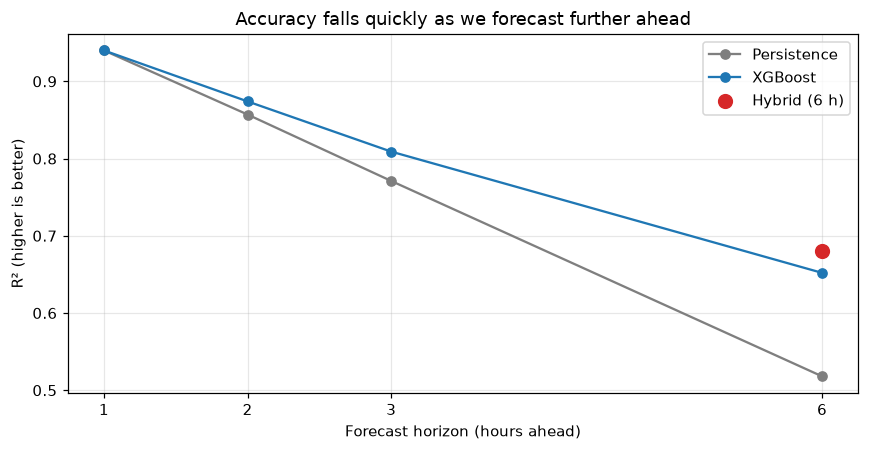

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(horizons.index, horizons["Persistence R2"], marker="o", color="tab:gray", label="Persistence")
ax.plot(horizons.index, horizons["XGBoost R2"], marker="o", color="tab:blue", label="XGBoost")
ax.scatter([6], [average_scores(scored["actual"], scored["Hybrid"], scored["fold"])["R2"]], color="tab:red", s=80, zorder=3, label="Hybrid (6 h)")
ax.set_xticks([1, 2, 3, 6])
ax.set_xlabel("Forecast horizon (hours ahead)")
ax.set_ylabel("R² (higher is better)")
ax.set_title("Accuracy falls quickly as we forecast further ahead")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG}/22_accuracy_by_horizon.png")
plt.show()

One hour ahead, even persistence reaches R² of about 0.94, so almost any model looks "90% accurate" there. Six hours ahead is much harder, and that is where our models add the most over persistence.

## Conclusion

- The biggest gains came from **what the network learns** (the 6-hour change, L1 loss) and from **averaging** (3 seeds, then the hybrid), not from bigger or more complex networks.
- Seven network designs, ARIMA and learned stacking weights all fail to beat the equal-weight **hybrid of XGBoost, LSTM and TCN**, which stays our final model.
- The remaining error comes from missing information (future weather, neighbouring stations), not from the model: a perfect weather forecast would raise R² clearly.